# S1 · Range-aware evaluation harness

This notebook validates every week-1 component and produces the artefacts that later weeks depend on:

1. a reproducible environment record;
2. an HU → SPR conversion identical to the one used by the SynthRAD2025 dose engine (pyRadPlan);
3. a differentiable water-equivalent-thickness (WET) projector, checked against analytic geometry, pyRadPlan's Siddon ray tracer and finite differences;
4. a frozen, hash-verified local test split;
5. per-case range diagnostics on the development pool.

All logic lives in the `sctrange` package; the notebook configures, runs and reports.
Set `SYNTHRAD2025_ROOT` to the dataset root (and optionally `SCT_PREDICTION_ROOT` to a folder of `<case_id>.mha` predictions).
Without the dataset, a synthetic fixture in the same layout is generated so that every cell executes; **fixture results validate the pipeline only and carry no scientific meaning.**

In [1]:
import json
import os
import platform
import subprocess
import warnings
from importlib import metadata
from pathlib import Path

warnings.filterwarnings("ignore", message=r"`torch\.jit\.script` is deprecated")
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk
import torch
from IPython.display import display
from pyRadPlan.ct import CT

from sctrange.data import bulk_density_sct, discover_cases, load_case, read_volume
from sctrange.evaluation import DiagnosticConfig, evaluate_case, prepare_case
from sctrange.hlut import HLUT
from sctrange.metrics import range_error
from sctrange.phantoms import write_fixture_dataset
from sctrange.plotting import apply_style, plot_case, plot_hlut, plot_mae_vs_range, plot_projector_checks
from sctrange.split import SplitSpec, load_split, split_hash, stratified_split, write_split
from sctrange.validation import (
    benchmark_range_loss,
    disk_chord_errors,
    gradcheck_range_loss,
    siddon_relative_errors,
    target_path_errors,
)

In [2]:
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
DATA_ROOT = Path(os.environ.get("SYNTHRAD2025_ROOT", REPO_ROOT / "data" / "synthrad2025"))
PREDICTION_ROOT = Path(os.environ["SCT_PREDICTION_ROOT"]) if "SCT_PREDICTION_ROOT" in os.environ else None
OUTPUT_DIR = REPO_ROOT / "outputs" / "s1"
FIGURE_DIR = OUTPUT_DIR / "figures"
FROZEN_SPLIT_PATH = REPO_ROOT / "splits" / "synthrad2025_local_test.json"

SEED = 20261013
TEST_FRACTION = 0.2
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
VALIDATION_ANGLES = (0.0, 17.0, 45.0, 90.0, 133.0, 210.0, 301.0)
SIDDON_ANGLES = (0.0, 60.0, 135.0)
DIAGNOSTIC = DiagnosticConfig(angles_deg=tuple(range(0, 360, 45)), target_radius_mm=25.0, seed=SEED, device=DEVICE)
MAX_CASES = None

torch.manual_seed(SEED)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
apply_style()

In [3]:
USE_FIXTURE = not DATA_ROOT.exists() or next(DATA_ROOT.rglob("ct.mha"), None) is None
if USE_FIXTURE:
    DATA_ROOT = OUTPUT_DIR / "fixture" / "data"
    PREDICTION_ROOT = OUTPUT_DIR / "fixture" / "predictions"
    if next(DATA_ROOT.rglob("ct.mha"), None) is None:
        write_fixture_dataset(DATA_ROOT, PREDICTION_ROOT, centers=("A", "B", "C"), cases_per_stratum=5, seed=SEED)
SPLIT_PATH = OUTPUT_DIR / "fixture_split.json" if USE_FIXTURE else FROZEN_SPLIT_PATH

print(f"data       : {DATA_ROOT}{'  [synthetic fixture]' if USE_FIXTURE else ''}")
print(f"predictions: {PREDICTION_ROOT}")
print(f"split      : {SPLIT_PATH}")
print(f"device     : {DEVICE}")

data       : outputs/s1/fixture/data  [synthetic fixture]
predictions: outputs/s1/fixture/predictions
split      : outputs/s1/fixture_split.json
device     : cpu


## 1 · Environment

Versions and the code revision are stored with every result so that any number can be traced back to the exact software that produced it.

In [4]:
def package_version(name: str) -> str:
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return "not installed"


def git_revision(root: Path) -> str:
    try:
        revision = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=root, capture_output=True,
                                  text=True, check=True).stdout.strip()
        dirty = subprocess.run(["git", "status", "--porcelain"], cwd=root, capture_output=True, text=True).stdout
        return revision + ("-dirty" if dirty.strip() else "")
    except (OSError, subprocess.CalledProcessError):
        return "no git repository"


environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "device": DEVICE,
    **{name: package_version(name) for name in ("numpy", "scipy", "SimpleITK", "pandas", "pyradplan", "sctrange")},
    "git_revision": git_revision(REPO_ROOT),
    "fixture": USE_FIXTURE,
}
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2))
display(pd.Series(environment, name="value").to_frame())

,value
python,3.11.4
platform,Windows-10-10.0.26200-SP0
torch,2.14.1+cpu
cuda_available,False
device,cpu
numpy,2.3.5
scipy,1.17.1
SimpleITK,2.5.6
pandas,3.0.3
pyradplan,0.5.0


## 2 · HU → SPR conversion

The range proxy must convert HU exactly as the dose engine does. The SynthRAD2025 dose evaluation uses pyRadPlan (v0.2.8), whose default table is identical in v0.5.0 and is applied with `np.interp`: linear interpolation, constant beyond the end nodes.

Checks: the bundled table equals the installed one; the NumPy and Torch paths reproduce `CT.compute_wet` on random HU, including out-of-range values; the curve is monotone with water at 1.

This is the engine's generic table, not a scanner-specific stoichiometric calibration. It is the right choice for consistency with the challenge dosimetry; if a calibrated curve is adopted, it must replace the table in both the proxy and the dose engine.

,value
fingerprint,645095e5027702e0
matches installed pyRadPlan,True
max |numpy - engine|,0.0
max |torch - engine|,0.0
monotone,True
SPR at 0 HU,1.0


,HU,SPR,slope to next node (1/HU)
0,-1024.0,0.001,0.000000
1,-999.0,0.001,0.001044
2,-90.0,0.950,0.000889
3,-45.0,0.990,0.000222
4,0.0,1.000,0.000950
5,100.0,1.095,0.000416
6,350.0,1.199,0.000493
7,3000.0,2.505,NaN


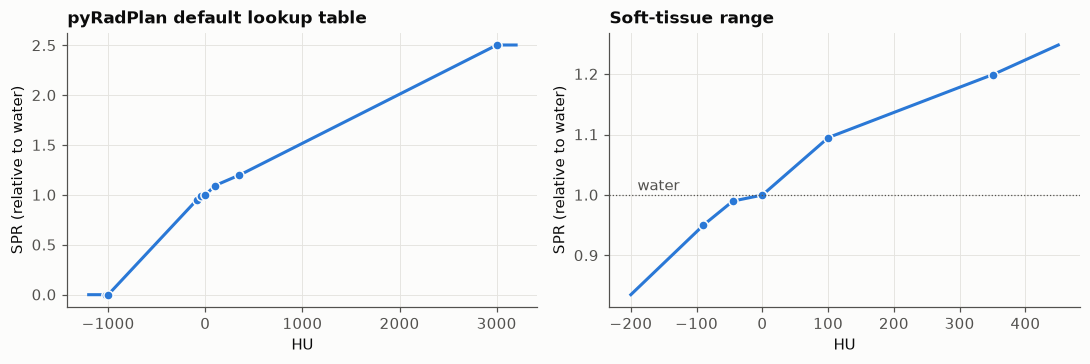

In [5]:
hlut = HLUT.pyradplan_default()
installed = HLUT.from_pyradplan()

probe = np.random.default_rng(SEED).uniform(-1500, 3500, size=(4, 32, 32)).astype(np.float32)
image = sitk.GetImageFromArray(probe)
image.SetSpacing((1.0, 1.0, 3.0))
engine = sitk.GetArrayFromImage(CT(cube_hu=image).compute_wet(np.stack([hlut.hu, hlut.spr], axis=1)))

hlut_checks = {
    "fingerprint": hlut.fingerprint(),
    "matches installed pyRadPlan": bool(np.array_equal(installed.hu, hlut.hu) and np.array_equal(installed.spr, hlut.spr)),
    "max |numpy - engine|": float(np.abs(hlut.numpy(probe) - engine).max()),
    "max |torch - engine|": float(np.abs(hlut.torch(torch.from_numpy(probe).double()).numpy() - engine).max()),
    "monotone": bool(np.all(np.diff(hlut.numpy(np.linspace(-2000, 4000, 6001))) >= 0)),
    "SPR at 0 HU": float(hlut.numpy(np.array(0.0))),
}
assert hlut_checks["matches installed pyRadPlan"] and hlut_checks["monotone"]
assert hlut_checks["max |numpy - engine|"] < 1e-12 and hlut_checks["max |torch - engine|"] < 1e-12
assert hlut_checks["SPR at 0 HU"] == 1.0

display(pd.Series(hlut_checks, name="value").to_frame())
display(pd.DataFrame({"HU": hlut.hu, "SPR": hlut.spr, "slope to next node (1/HU)": np.append(hlut.slopes(), np.nan)}))
plot_hlut(hlut).savefig(FIGURE_DIR / "hlut.png", bbox_inches="tight")
plt.show()

## 3 · Differentiable WET projector

Each axial slice is padded to a square canvas and rotated with `grid_sample` so that the beam travels along the row axis; a masked sum over rows gives one integral per ray, in millimetres of water. Segments run from beam entry either to the body exit (*chord*) or to the distal edge of the target (*target*), the latter being what governs the range of a proton stopping in the target.

Four independent checks:

| Check | Reference | Criterion |
|---|---|---|
| Disk chords | exact chord length `2√(R² − u²)` | median < 0.1 mm, max < 0.5 mm |
| Target segments | `√(R² − u²) + √(r² − u²)` | max < 1.5 mm (one pixel at the distal edge) |
| Heterogeneous phantom | pyRadPlan Siddon tracer (water, lung and bone inserts) | median < 1 %, max < 4 % |
| Gradient | finite differences in float64 | `torch.autograd.gradcheck` passes |

,value
chord median |error| (mm),0.08141
chord max |error| (mm),0.366756
target max |error| (mm),1.044483
target rays valid inside / none outside,True
Siddon median relative error,0.000883
Siddon max relative error,0.00677
Siddon rays compared,57
gradcheck,True


,angle_deg,rays chord,median_abs_mm chord,max_abs_mm chord,rays target,median_abs_mm target,max_abs_mm target,valid_inside,valid_outside
0,0.0,83,0.043,0.231,25,0.279,1.044,True,False
1,17.0,84,0.046,0.367,26,0.213,0.864,True,False
2,45.0,84,0.081,0.229,26,0.361,0.618,True,False
3,90.0,83,0.043,0.231,25,0.279,1.044,True,False
4,133.0,84,0.055,0.259,26,0.209,0.801,True,False
5,210.0,84,0.063,0.234,26,0.291,0.781,True,False
6,301.0,84,0.070,0.185,26,0.197,0.791,True,False


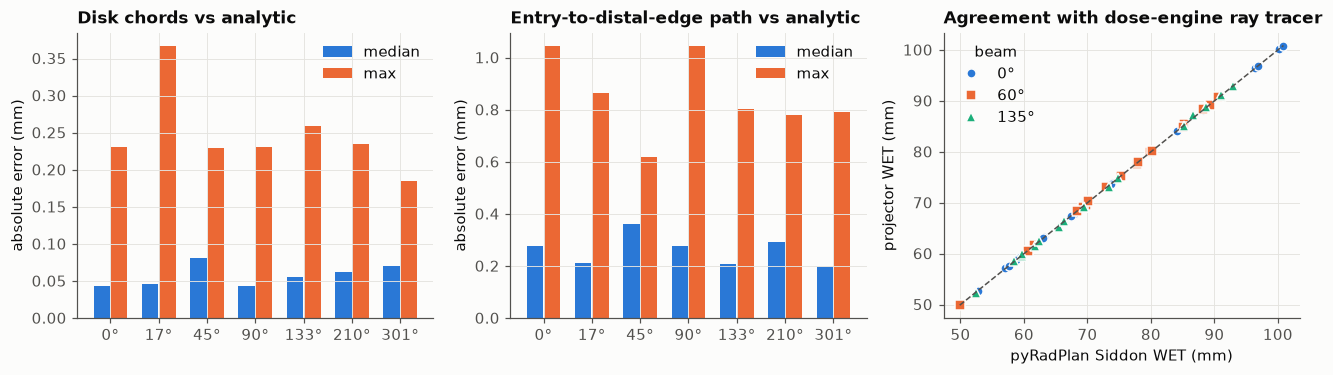

In [6]:
chord = disk_chord_errors(VALIDATION_ANGLES)
target = target_path_errors(VALIDATION_ANGLES)
siddon = siddon_relative_errors(hlut, SIDDON_ANGLES)

projector_checks = {
    "chord median |error| (mm)": chord["median_abs_mm"].max(),
    "chord max |error| (mm)": chord["max_abs_mm"].max(),
    "target max |error| (mm)": target["max_abs_mm"].max(),
    "target rays valid inside / none outside": bool(target["valid_inside"].all() and not target["valid_outside"].any()),
    "Siddon median relative error": siddon["relative_error"].median(),
    "Siddon max relative error": siddon["relative_error"].max(),
    "Siddon rays compared": len(siddon),
    "gradcheck": gradcheck_range_loss(hlut, SEED),
}
assert projector_checks["chord median |error| (mm)"] < 0.1 and projector_checks["chord max |error| (mm)"] < 0.5
assert projector_checks["target max |error| (mm)"] < 1.5 and projector_checks["target rays valid inside / none outside"]
assert projector_checks["Siddon median relative error"] < 0.01 and projector_checks["Siddon max relative error"] < 0.04
assert projector_checks["gradcheck"]

display(pd.Series(projector_checks, name="value").to_frame())
display(chord.merge(target, on="angle_deg", suffixes=(" chord", " target")).round(3))
plot_projector_checks(chord, target, siddon).savefig(FIGURE_DIR / "projector_checks.png", bbox_inches="tight")
plt.show()

Cost of one range-loss forward and backward pass on a cropped volume of typical SynthRAD2025 size (16 slices of 380 × 480 at 1 mm, three beams), on the active device.

In [7]:
benchmark = benchmark_range_loss(hlut, (16, 380, 480), (0.0, 120.0, 240.0), device=DEVICE)
display(pd.Series(benchmark, name="value").to_frame())

,value
slices,16.0000
height,380.0000
width,480.0000
angles,3.0000
forward_ms,175.3411
backward_ms,225.4635


## 4 · Frozen local test split

SynthRAD2025 keeps its test ground truth private, so model selection needs a local hold-out drawn from the public training cases. The split is stratified by task, region and centre and uses an independent seed per stratum, so adding cases to one stratum never moves cases in another. It is written once with its SHA-256, committed, and only verified afterwards: `load_split` refuses a modified file.

On the real dataset the canonical file is `splits/synthrad2025_local_test.json`. It can also be produced from the command line and committed:

```bash
sctrange-split --data-root "$SYNTHRAD2025_ROOT" --out splits/synthrad2025_local_test.json
git add splits/ && git commit -m "Freeze SynthRAD2025 local test split"
```

Fixture runs write to `outputs/` so that they can never be mistaken for the frozen split.

In [8]:
records = discover_cases(DATA_ROOT)
available = {record.case_id for record in records}

if SPLIT_PATH.exists():
    split = load_split(SPLIT_PATH)
    split_status = "verified existing split"
else:
    split = stratified_split(records, SplitSpec(test_fraction=TEST_FRACTION, seed=SEED))
    write_split(split, SPLIT_PATH)
    split = load_split(SPLIT_PATH)
    split_status = "created and verified"

assigned = set(split["test"]) | set(split["development"])
split_summary = {
    "status": split_status,
    "sha256": split_hash(split),
    "test cases": len(split["test"]),
    "development cases": len(split["development"]),
    "cases on disk not in split": len(available - assigned),
    "split cases missing on disk": len(assigned - available),
}
assert not set(split["test"]) & set(split["development"])

display(pd.Series(split_summary, name="value").to_frame())
display(pd.DataFrame(split["strata"]).T.rename_axis("stratum"))

,value
status,created and verified
sha256,1d1a8dd4bb68b3d1e366125a2afbff70aa43e5a462e5f1...
test cases,9
development cases,36
cases on disk not in split,0
split cases missing on disk,0


,test,total
stratum,,
task1/AB/A,1,5
task1/AB/B,1,5
task1/AB/C,1,5
task1/HN/A,1,5
task1/HN/B,1,5
task1/HN/C,1,5
task1/TH/A,1,5
task1/TH/B,1,5
task1/TH/C,1,5


## 5 · Range diagnostics on the development pool

Test cases are never loaded here. For each development case, the bulk-density baseline (water inside the body, as in the challenge) and, when available, a prediction are compared with the reference CT. SynthRAD2025 releases no PTV, so a 25 mm sphere at the body centroid serves as a surrogate target defining the distal edge.

Per case and source:

- `mae_hu`: mean absolute HU error in the body;
- `*_rms_mm`, `*_p95_mm`, `*_cvar_mm`: RMS, 95th percentile and upper-decile mean of |ΔWET| over rays, for chords and target segments;
- `*_coherence`: median of |Σε| / Σ|ε| along rays, close to 1/√n for white errors and to 1 for errors that accumulate;
- `*_intra_ratio`, `*_global_ratio`: RMS ΔWET divided by that of the same errors shuffled within tissue classes, or globally. Both shuffles leave the MAE unchanged, so a ratio away from 1 shows that range error depends on the spatial layout of errors and not only on their magnitude.

In [9]:
development = [record for record in records if record.case_id in set(split["development"])][:MAX_CASES]
prediction_label = "prediction (synthetic)" if USE_FIXTURE else "prediction"

rows = []
for record in development:
    volumes = load_case(record, ("ct", "mask"))
    ct, mask, spacing = volumes["ct"].array, volumes["mask"].array, volumes["ct"].spacing
    sources = {"bulk density": bulk_density_sct(mask)}
    if PREDICTION_ROOT is not None and (PREDICTION_ROOT / f"{record.case_id}.mha").exists():
        sources[prediction_label] = read_volume(PREDICTION_ROOT / f"{record.case_id}.mha").array
    for source, sct in sources.items():
        metrics = evaluate_case(ct, mask, sct, spacing, hlut, DIAGNOSTIC)
        rows.append({"case_id": record.case_id, "region": record.region, "center": record.center,
                     "source": source, **metrics})

diagnostics = pd.DataFrame(rows)
diagnostics.to_csv(OUTPUT_DIR / "range_diagnostics.csv", index=False)
print(f"{diagnostics['case_id'].nunique()} development cases, {len(diagnostics)} evaluations")

columns = ["mae_hu", "chord_rms_mm", "target_rms_mm", "target_cvar_mm", "target_coherence",
           "target_intra_ratio", "target_global_ratio"]
display(diagnostics.groupby(["source", "region"])[columns].mean().round(3))

36 development cases, 72 evaluations


mae_hu  chord_rms_mm  target_rms_mm  \
source                 region                                         
bulk density           AB       79.885         6.026          6.271   
                       HN      234.367        11.742          6.836   
                       TH      404.702        55.223         44.815   
prediction (synthetic) AB       38.984         2.584          1.790   
                       HN       80.788         2.961          1.974   
                       TH       74.481         4.971          3.808   

                               target_cvar_mm  target_coherence  \
source                 region                                     
bulk density           AB              13.487             0.719   
                       HN              11.239             0.861   
                       TH              68.256             0.891   
prediction (synthetic) AB               3.425             0.394   
                       HN               3.236             0.500   
                       TH               6.457             0.470   

                               target_intra_ratio  target_global_ratio  
source                 region                                           
bulk density           AB                   1.059                2.816  
                       HN                   1.087                0.588  
                       TH                   0.993                1.869  
prediction (synthetic) AB                   1.144                1.613  
                       HN                   1.018                1.025  
                       TH                   1.168                1.679

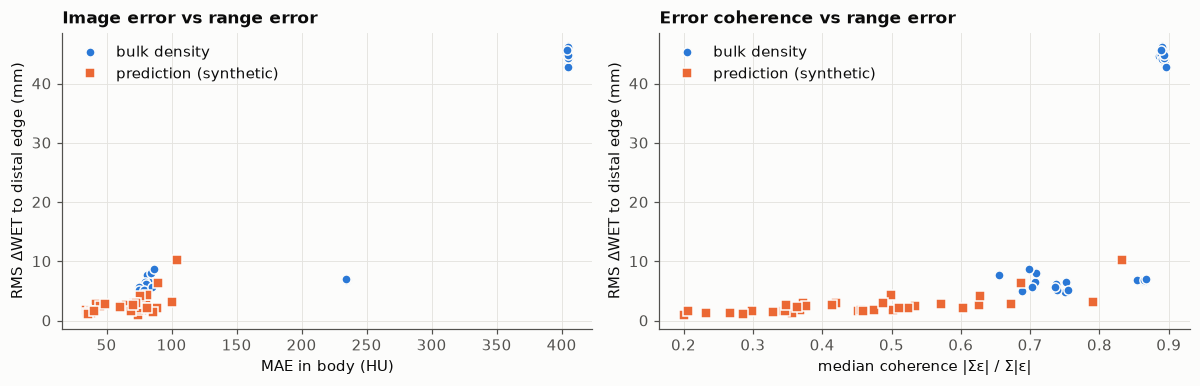

mae_hu  target_rms_mm  \
source                                                           
bulk density           mae_hu             1.000          0.834   
                       target_rms_mm      0.834          1.000   
                       target_coherence   0.883          0.713   
prediction (synthetic) mae_hu             1.000          0.508   
                       target_rms_mm      0.508          1.000   
                       target_coherence   0.602          0.761   

                                         target_coherence  
source                                                     
bulk density           mae_hu                       0.883  
                       target_rms_mm                0.713  
                       target_coherence             1.000  
prediction (synthetic) mae_hu                       0.602  
                       target_rms_mm                0.761  
                       target_coherence             1.000

In [10]:
plot_mae_vs_range(diagnostics).savefig(FIGURE_DIR / "mae_vs_range.png", bbox_inches="tight")
plt.show()
display(diagnostics.groupby("source")[["mae_hu", "target_rms_mm", "target_coherence"]]
        .corr(method="spearman").round(3))

One development case in detail: reference slice, signed HU error, and signed ΔWET per ray to the distal target edge for the first three beams. The slice shown is the one with the most target rays.

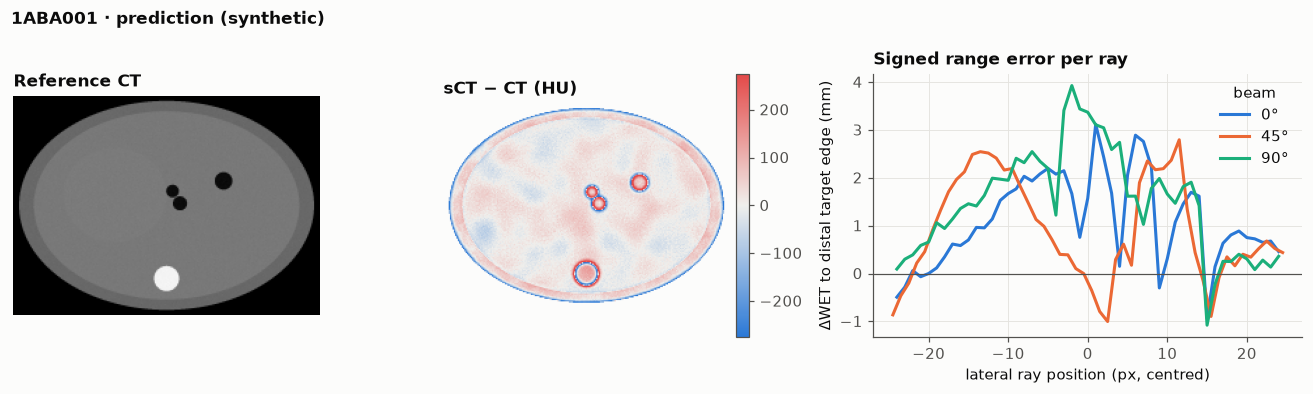

In [11]:
example = next((row for row in rows if row["source"] == prediction_label), rows[0])
record = next(r for r in development if r.case_id == example["case_id"])
volumes = load_case(record, ("ct", "mask"))
sct = (read_volume(PREDICTION_ROOT / f"{record.case_id}.mha").array if example["source"] == prediction_label
       else bulk_density_sct(volumes["mask"].array))
case = prepare_case(volumes["ct"].array, volumes["mask"].array, sct, volumes["ct"].spacing, DIAGNOSTIC)
result = range_error(case.sct, case.ct, case.mask, case.projector, hlut, case.target)
slice_index = int(result.valid.sum(dim=(0, 2)).argmax())

plot_case(case.ct.cpu().numpy(), case.sct.cpu().numpy(), case.mask.cpu().numpy(),
          result.delta_mm.cpu().numpy(), result.valid.cpu().numpy(), DIAGNOSTIC.angles_deg,
          slice_index, f"{record.case_id} · {example['source']}").savefig(FIGURE_DIR / "example_case.png", bbox_inches="tight")
plt.show()

## 6 · S1 status

Every item is evaluated from the results above and written to `outputs/s1/s1_report.json` with the environment record.

In [12]:
status = pd.DataFrame([
    ("pyRadPlan installed", environment["pyradplan"], environment["pyradplan"] != "not installed"),
    ("HU → SPR identical to dose engine", f"fingerprint {hlut.fingerprint()}",
     hlut_checks["max |numpy - engine|"] < 1e-12 and hlut_checks["max |torch - engine|"] < 1e-12),
    ("Projector vs analytic chords", f"max {projector_checks['chord max |error| (mm)']:.3f} mm",
     projector_checks["chord max |error| (mm)"] < 0.5),
    ("Target segments to distal edge", f"max {projector_checks['target max |error| (mm)']:.3f} mm",
     projector_checks["target max |error| (mm)"] < 1.5),
    ("Projector vs pyRadPlan Siddon", f"median {projector_checks['Siddon median relative error']:.2%}",
     projector_checks["Siddon median relative error"] < 0.01),
    ("Gradient check", "float64 finite differences", projector_checks["gradcheck"]),
    ("Local test split", f"{split_summary['status']} · sha256 {split_summary['sha256'][:12]}",
     split_summary["split cases missing on disk"] == 0),
    ("Frozen split on real data", str(SPLIT_PATH.relative_to(REPO_ROOT)), not USE_FIXTURE),
    ("Range diagnostics", f"{len(diagnostics)} evaluations", len(diagnostics) > 0),
], columns=["item", "detail", "passed"])

report = {"environment": environment, "hlut": hlut_checks, "projector": projector_checks,
          "benchmark": benchmark, "split": split_summary,
          "status": status.to_dict(orient="records")}
(OUTPUT_DIR / "s1_report.json").write_text(json.dumps(report, indent=2, default=str))
display(status)

,item,detail,passed
0,pyRadPlan installed,0.5.0,True
1,HU → SPR identical to dose engine,fingerprint 645095e5027702e0,True
2,Projector vs analytic chords,max 0.367 mm,True
3,Target segments to distal edge,max 1.044 mm,True
4,Projector vs pyRadPlan Siddon,median 0.09%,True
5,Gradient check,float64 finite differences,True
6,Local test split,created and verified · sha256 1d1a8dd4bb68,True
7,Frozen split on real data,outputs\s1\fixture_split.json,False
8,Range diagnostics,72 evaluations,True
